# Practical 5: Matrix Multiplication (Pattern 2)

### 1. Aim
To multiply three independent pairs of matrices of dimension 720x720 using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of 720x720 integer matrices.<br>2. Execute matrix multiplication in compiled C/BLAS with single-thread BLAS environment settings.<br>3. Sequential: multiply Pair 1 -> Pair 2 -> Pair 3.<br>4. Pool: distribute to 3 workers in `mp.Pool(3)`.<br>5. Process: compute using 3 separate `mp.Process` instances.<br>6. Thread: compute concurrently with 3 `threading.Thread` workers.<br>7. Benchmark execution times and compute speedup.

### 3. Python Implementation


In [1]:
"""
Practical 5: Matrix Multiplication (Pattern 2)
Three independent tasks: A1xB1, A2xB2, A3xB3
Four methods: Sequential, Pool, Process, Thread
"""
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matmul_task(task):
    n, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    B = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    # BLAS matrix product in C (releases GIL)
    C = np.matmul(A, B)
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matmul_task(task))

def thread_worker(task, results, idx):
    results[idx] = matmul_task(task)

def main():
    print("=" * 60)
    print("Practical 5: Matrix Multiplication (Pattern 2)")
    print("=" * 60)
    N = 720
    tasks = [(N, 11), (N, 22), (N, 33)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matmul_task(tasks[0])
    r2 = matmul_task(tasks[1])
    r3 = matmul_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matmul_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Matrix Dimension: {N}x{N} across 3 independent pairs.")
    print(f"Verification: Sequential={seq_res[0]} | Thread={thread_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 5: Matrix Multiplication (Pattern 2)
Matrix Dimension: 720x720 across 3 independent pairs.
Verification: Sequential=69203 | Thread=69203
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.8044 seconds      1.00x
Pool         1.4963 seconds      1.87x
Process      1.4925 seconds      1.88x
Thread       0.7933 seconds      3.54x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


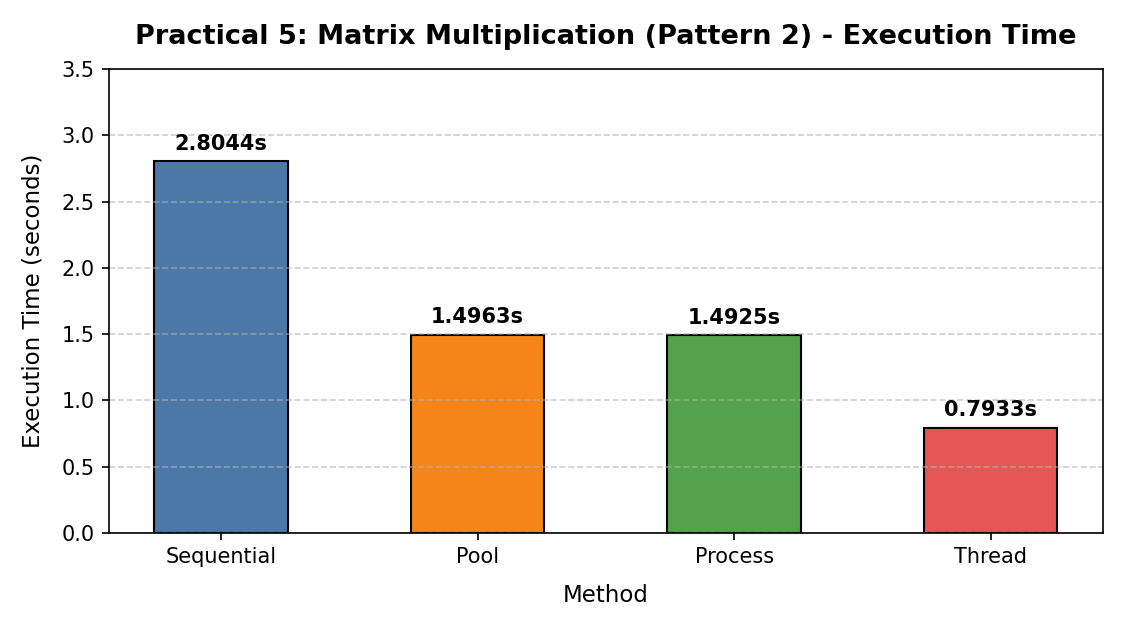

In [2]:
from IPython.display import Image, display
display(Image(filename='05_matrix_multiplication_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


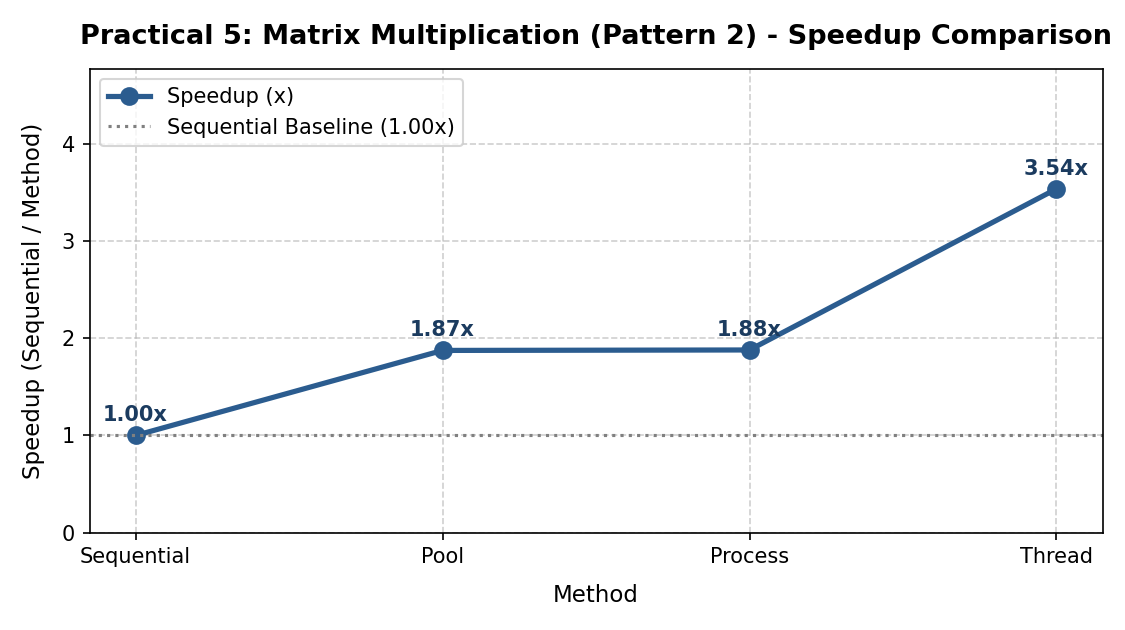

In [3]:
from IPython.display import Image, display
display(Image(filename='05_matrix_multiplication_speedup.png'))
